| **Inicio**         | **atrás 5**                          |
| ------------------ | ------------------------------------ |
| [🏠](../README.md) | [⏪](./2_5_SVD.ipynb) |

# 0. La idea central: ¿por qué necesitamos álgebra lineal numérica?

Supongamos que tienes una PDE:

$$
-\frac{d^2u}{dx^2}=f(x).
$$

Al discretizar el dominio:

$$
x_0,x_1,\ldots,x_N
$$

terminas con algo parecido a:

$$
A\mathbf u=\mathbf f.
$$

Por ejemplo:

$$
\begin{bmatrix}
2&-1&0&0\\
-1&2&-1&0\\
0&-1&2&-1\\
0&0&-1&2
\end{bmatrix}
\begin{bmatrix}
u_1\\u_2\\u_3\\u_4
\end{bmatrix}
=
\begin{bmatrix}
f_1\\f_2\\f_3\\f_4
\end{bmatrix}.
$$

Esto parece pequeño.

Pero en una simulación científica real podrías tener:

$$
N=10^6
$$

o incluso mucho más.

Entonces la pregunta cambia de:

> "¿Existe una solución?"

a:

> **"¿Cómo calculo esa solución sin gastar horas o días y sin introducir errores numéricos?"**

Ahí aparece el álgebra lineal numérica.

# 1. LU DECOMPOSITION

## 1.1 ¿Qué es LU?

La factorización LU intenta escribir:

$$
A=LU
$$

donde:

* $(L)$ = matriz triangular inferior
* $(U)$ = matriz triangular superior

Por ejemplo:

$$
L=
\begin{bmatrix}
1&0&0\\
l_{21}&1&0\\
l_{31}&l_{32}&1
\end{bmatrix}
$$

y

$$
U=
\begin{bmatrix}
u_{11}&u_{12}&u_{13}\\
0&u_{22}&u_{23}\\
0&0&u_{33}
\end{bmatrix}.
$$

La gran ventaja es que resolver

$$
Ax=b
$$

se convierte en:

$$
LUx=b.
$$

Definimos:

$$
Ly=b
$$

y después:

$$
Ux=y.
$$

Es decir:

$$
\boxed{Ax=b\rightarrow Ly=b\rightarrow Ux=y}
$$

Son dos sistemas triangulares mucho más fáciles de resolver.

# 1.2 Ejemplo difícil a mano

Consideremos:

$$
A=
\begin{bmatrix}
4&3&2\\
8&7&6\\
4&5&8
\end{bmatrix}.
$$

Queremos:

$$
A=LU.
$$

Usamos eliminación de Gauss.

Primer pivote:

$$
a_{11}=4.
$$

Multiplicador:

$$
m_{21}=\frac84=2
$$

y

$$
m_{31}=\frac44=1.
$$

Entonces:

$$
R_2\leftarrow R_2-2R_1
$$

produce:

$$
[0,1,2].
$$

Y:

$$
R_3\leftarrow R_3-R_1
$$

produce:

$$
[0,2,6].
$$

Ahora usamos el segundo pivote:

$$
m_{32}=\frac21=2.
$$

Entonces:

$$
R_3\leftarrow R_3-2R_2
$$

produce:

$$
[0,0,2].
$$

Por tanto:

$$
U=
\begin{bmatrix}
4&3&2\\
0&1&2\\
0&0&2
\end{bmatrix}.
$$

Los multiplicadores forman:

$$
L=
\begin{bmatrix}
1&0&0\\
2&1&0\\
1&2&1
\end{bmatrix}.
$$

Comprueba:

$$
LU=
\begin{bmatrix}
4&3&2\\
8&7&6\\
4&5&8
\end{bmatrix}.
$$

# 1.3 ¿Por qué LU es útil?

Supón que tienes la misma matriz $(A)$, pero 10 000 vectores $(b)$:

$$
Ax_1=b_1
$$

$$
Ax_2=b_2
$$

$$
\vdots
$$

$$
Ax_{10000}=b_{10000}.
$$

No quieres hacer eliminación de Gauss desde cero 10 000 veces.

Haces:

$$
A=LU
$$

**una sola vez**.

Después resuelves:

$$
Ly_i=b_i
$$

y:

$$
Ux_i=y_i.
$$

Esto aparece muchísimo en simulaciones científicas.

# 1.4 LU con pivotamiento

En computación normalmente no usamos simplemente:

$$
A=LU.
$$

Usamos:

$$
\boxed{PA=LU}
$$

donde $(P)$ es una matriz de permutación.

¿Por qué?

Porque podríamos encontrarnos con:

$$
A=
\begin{bmatrix}
0&1\\
1&1
\end{bmatrix}.
$$

No puedes dividir por el primer pivote:

$$
a_{11}=0.
$$

Intercambiamos filas.

Esto conduce al **partial pivoting**.

Es importantísimo para estabilidad numérica.

# 1.5 Python

In [1]:
import numpy as np
from scipy.linalg import lu

A = np.array([
    [4., 3., 2.],
    [8., 7., 6.],
    [4., 5., 8.]
])

P, L, U = lu(A)

print("P =")
print(P)

print("\nL =")
print(L)

print("\nU =")
print(U)

print("\nError:")
print(np.linalg.norm(P @ L @ U - A))

P =
[[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]

L =
[[ 1.          0.          0.        ]
 [ 0.5         1.          0.        ]
 [ 0.5        -0.33333333  1.        ]]

U =
[[8.         7.         6.        ]
 [0.         1.5        5.        ]
 [0.         0.         0.66666667]]

Error:
0.0


La idea importante:

```python
P @ L @ U
```

debe reconstruir \(A\).

# 1.6 Aplicación real: simulación de temperatura

Imagina una placa metálica.

La ecuación:

$$
\nabla^2T=0
$$

describe temperatura estacionaria.

Después de discretizar:

$$
A\mathbf T=\mathbf b.
$$

LU puede resolver este sistema.

Esto aparece en:

* transferencia de calor,
* estructuras,
* fluidos,
* electromagnetismo,
* elasticidad,
* simulación física.

# 2. QR DECOMPOSITION

Ahora viene una factorización fundamental para **regresión, mínimos cuadrados, optimización y machine learning**.

$$
\boxed{A=QR}
$$

donde:

$$
Q^TQ=I
$$

y $(R)$ es triangular superior.

# 2.1 ¿Por qué queremos $(Q)$?

Porque las columnas de $(Q)$ son ortonormales:

$$
q_i^Tq_j=
\begin{cases}
1&i=j\\
0&i\neq j.
\end{cases}
$$

Esto hace que los cálculos sean numéricamente mucho más estables.

# 2.2 Ejemplo

Considera:

$$
A=
\begin{bmatrix}
1&1\\
1&0\\
0&1
\end{bmatrix}.
$$

Queremos construir una base ortonormal.

Primera columna:

$$
a_1=
\begin{bmatrix}
1\\1\\0
\end{bmatrix}.
$$

Su norma:

$$
\|a_1\|=\sqrt2.
$$

Entonces:

$$
q_1=
\frac{a_1}{\sqrt2}
=
\begin{bmatrix}
1/\sqrt2\\
1/\sqrt2\\
0
\end{bmatrix}.
$$

Ahora:

$$
a_2=
\begin{bmatrix}
1\\0\\1
\end{bmatrix}.
$$

Proyectamos:

$$
\operatorname{proj}_{q_1}(a_2)
=
(q_1^Ta_2)q_1.
$$

Tenemos:

$$
q_1^Ta_2=\frac1{\sqrt2}.
$$

Por tanto:

$$
u_2=
a_2-\frac1{\sqrt2}q_1.
$$

Después normalizamos:

$$
q_2=\frac{u_2}{\|u_2\|}.
$$

Finalmente:

$$
Q=
\begin{bmatrix}
q_1&q_2
\end{bmatrix}.
$$

# 2.3 QR y mínimos cuadrados

Esto es **extremadamente importante para ML**.

Tenemos:

$$
X\beta\approx y.
$$

Queremos minimizar:

$$
\boxed{
\min_\beta\|X\beta-y\|_2^2
}
$$

La solución mediante ecuaciones normales es:

$$
X^TX\beta=X^Ty.
$$

Pero computacionalmente hay un problema:

$$
\kappa(X^TX)=\kappa(X)^2.
$$

Es decir, podemos empeorar muchísimo el conditioning.

QR permite:

$$
X=QR.
$$

Entonces:

$$
X\beta\approx y
$$

se convierte en:

$$
QR\beta\approx y.
$$

Multiplicamos por $(Q^T)$:

$$
R\beta=Q^Ty.
$$

Y como $(R)$ es triangular superior:

$$
\boxed{\beta=R^{-1}Q^Ty}
$$

sin formar explícitamente $(X^TX)$.

# 2.4 Esto aparece en ML

Por ejemplo:

$$
y=\beta_0+\beta_1x+\beta_2x^2+\beta_3x^3+\epsilon.
$$

Construyes:

$$
X=
\begin{bmatrix}
1&x_1&x_1^2&x_1^3\\
1&x_2&x_2^2&x_2^3\\
\vdots&\vdots&\vdots&\vdots\\
1&x_n&x_n^2&x_n^3
\end{bmatrix}.
$$

Entonces:

$$
X\beta\approx y.
$$

QR encuentra los coeficientes.

# 2.5 Python

In [2]:
import numpy as np

A = np.array([
    [1., 1.],
    [1., 0.],
    [0., 1.]
])

Q, R = np.linalg.qr(A)

print("Q:")
print(Q)

print("\nR:")
print(R)

print("\nQ^T Q:")
print(Q.T @ Q)

print("\nReconstrucción:")
print(np.linalg.norm(Q @ R - A))

Q:
[[-0.70710678  0.40824829]
 [-0.70710678 -0.40824829]
 [-0.          0.81649658]]

R:
[[-1.41421356 -0.70710678]
 [ 0.          1.22474487]]

Q^T Q:
[[1.00000000e+00 1.02766874e-16]
 [1.02766874e-16 1.00000000e+00]]

Reconstrucción:
6.716134489646879e-16


Debes obtener:

$$
Q^TQ\approx I.
$$

# 2.6 QR en SciML

Supón que estás ajustando parámetros de una ecuación física:

$$
u(x;\theta)
$$

a datos experimentales:

$$
u_{\text{observado}}.
$$

Puedes terminar resolviendo:

$$
\min_\theta\|F(\theta)-y\|^2.
$$

Los métodos basados en QR aparecen en:

* parameter estimation,
* least squares,
* optimization,
* inverse problems,
* system identification,
* data assimilation.

# 3. CHOLESKY

Ahora una factorización preciosa:

$$
\boxed{A=LL^T}
$$

pero **no para cualquier matriz**.

Necesitamos que $(A)$ sea:

$$
\boxed{A=A^T,\qquad A\succ0}
$$

es decir:

* simétrica,
* definida positiva.

# 3.1 Ejemplo

Considera:

$$
A=
\begin{bmatrix}
4&2\\
2&5
\end{bmatrix}.
$$

Queremos:

$$
A=LL^T.
$$

Supongamos:

$$
L=
\begin{bmatrix}
l_{11}&0\\
l_{21}&l_{22}
\end{bmatrix}.
$$

Entonces:

$$
LL^T=
\begin{bmatrix}
l_{11}^2&l_{11}l_{21}\\
l_{11}l_{21}&l_{21}^2+l_{22}^2
\end{bmatrix}.
$$

Igualamos:

$$
l_{11}^2=4
$$

por tanto:

$$
l_{11}=2.
$$

Después:

$$
2l_{21}=2
$$

por tanto:

$$
l_{21}=1.
$$

Finalmente:

$$
1+l_{22}^2=5.
$$

Entonces:

$$
l_{22}=2.
$$

Por tanto:

$$
\boxed{
L=
\begin{bmatrix}
2&0\\
1&2
\end{bmatrix}
}
$$

y:

$$
LL^T=
\begin{bmatrix}
4&2\\
2&5
\end{bmatrix}.
$$

# 3.2 ¿Por qué Cholesky es tan importante?

Es aproximadamente **la mitad del trabajo de LU** para este tipo de matrices y aprovecha la estructura:

$$
A=A^T.
$$

Aparece muchísimo en:

### Optimización

Si:

$$
H=\nabla^2 f(x)
$$

es definida positiva, Cholesky puede factorizar $(H)$.

### Estadística

Matrices de covarianza:

$$
\Sigma\succ0.
$$

### Gaussian Processes

La matriz kernel:

$$
K_{ij}=k(x_i,x_j)
$$

normalmente debe ser positiva semidefinida.

### Element Element / FEM

Las matrices de rigidez frecuentemente tienen estructura simétrica positiva definida después de imponer condiciones apropiadas.

# 3.3 Python

In [3]:
import numpy as np

A = np.array([
    [4., 2.],
    [2., 5.]
])

L = np.linalg.cholesky(A)

print(L)

print("\nReconstrucción:")
print(L @ L.T)

print("\nError:")
print(np.linalg.norm(A - L @ L.T))

[[2. 0.]
 [1. 2.]]

Reconstrucción:
[[4. 2.]
 [2. 5.]]

Error:
0.0


# 4. MÉTODOS ITERATIVOS

Aquí cambia completamente la filosofía.

Con LU haces:

$$
Ax=b
$$

y buscas una solución directamente mediante factorización.

Con métodos iterativos haces:

$$
x^{(0)}
\rightarrow
x^{(1)}
\rightarrow
x^{(2)}
\rightarrow
\cdots
\rightarrow
x^*.
$$

# 4.1 ¿Por qué?

Porque si:

$$
A\in\mathbb R^{1\,000\,000\times1\,000\,000}
$$

hacer una factorización directa puede ser carísimo.

Entonces buscamos:

$$
x_k\to x^*
$$

sin almacenar todos los elementos de $(A)$.

# 4.2 Jacobi

Considera:

$$
Ax=b.
$$

Separaremos:

$$
A=D+L+U.
$$

Entonces:

$$
Dx=-(L+U)x+b.
$$

Por tanto:

$$
\boxed{
x^{(k+1)}
=
D^{-1}
[b-(L+U)x^{(k)}]
}
$$

# 4.3 Ejemplo

Considera:

$$
A=
\begin{bmatrix}
10&-1&2\\
-1&11&-1\\
2&-1&10
\end{bmatrix}
$$

y:

$$
b=
\begin{bmatrix}
6\\25\\-11
\end{bmatrix}.
$$

Comenzamos:

$$
x^{(0)}=
\begin{bmatrix}
0\\0\\0
\end{bmatrix}.
$$

Las ecuaciones son:

$$
10x_1-x_2+2x_3=6
$$

$$
-x_1+11x_2-x_3=25
$$

$$
2x_1-x_2+10x_3=-11.
$$

Despejamos:

$$
x_1^{(k+1)}
=
\frac{6+x_2^{(k)}-2x_3^{(k)}}{10}
$$

$$
x_2^{(k+1)}
=
\frac{25+x_1^{(k)}+x_3^{(k)}}{11}
$$

$$
x_3^{(k+1)}
=
\frac{-11-2x_1^{(k)}+x_2^{(k)}}{10}.
$$

# 4.4 El error y residual

Esto es importantísimo.

Podemos medir:

$$
e^{(k)}=x^{(k)}-x^*
$$

pero normalmente no conocemos $(x^*)$.

Entonces usamos el **residual**:

$$
\boxed{
r^{(k)}=b-Ax^{(k)}
}
$$

y:

$$
\|r^{(k)}\|_2
$$

nos dice qué tan bien satisface la ecuación.

# 4.5 Gráfico en Python

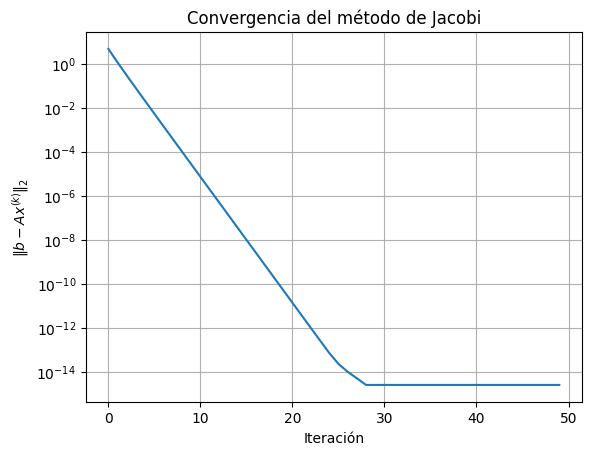

In [4]:
import numpy as np
import matplotlib.pyplot as plt

A = np.array([
    [10., -1., 2.],
    [-1., 11., -1.],
    [2., -1., 10.]
])

b = np.array([6., 25., -11.])

x = np.zeros(3)

residuals = []

for k in range(50):

    x_new = np.zeros_like(x)

    x_new[0] = (6 + x[1] - 2*x[2]) / 10
    x_new[1] = (25 + x[0] + x[2]) / 11
    x_new[2] = (-11 - 2*x[0] + x[1]) / 10

    x = x_new

    residual = np.linalg.norm(b - A @ x)
    residuals.append(residual)

plt.figure()
plt.semilogy(residuals)
plt.xlabel("Iteración")
plt.ylabel(r"$\|b-Ax^{(k)}\|_2$")
plt.title("Convergencia del método de Jacobi")
plt.grid()
plt.show()

La gráfica debería mostrar el residual disminuyendo.

# 4.6 Gauss-Seidel

Jacobi utiliza exclusivamente:

$$
x^{(k)}.
$$

Gauss-Seidel utiliza inmediatamente los valores nuevos:

$$
x_1^{(k+1)}
$$

y luego lo usa para calcular:

$$
x_2^{(k+1)}.
$$

Esto generalmente acelera la convergencia.

# 4.7 Conjugate Gradient

Para SciML esto es todavía más importante.

Si:

$$
A=A^T
$$

y:

$$
A\succ0,
$$

podemos utilizar:

$$
\boxed{\text{Conjugate Gradient}}
$$

CG evita factorizar $(A)$ y busca la solución mediante direcciones conjugadas.

El problema:

$$
Ax=b
$$

también puede verse como minimizar:

$$
f(x)=
\frac12x^TAx-b^Tx.
$$

Entonces:

$$
\nabla f(x)=Ax-b.
$$

La solución satisface:

$$
\nabla f(x)=0.
$$

Es decir:

$$
Ax=b.
$$

**Aquí aparece la conexión entre álgebra lineal y optimización.**

# 5. MATRICES DISPERSAS — SPARSE MATRICES

Esta parte es **fundamental para SciML**.

Una matriz densa:

$$
A=
\begin{bmatrix}
1&2&3&4\\
5&6&7&8\\
9&10&11&12\\
13&14&15&16
\end{bmatrix}
$$

tiene prácticamente todos sus elementos diferentes de cero.

Una sparse:

$$
A=
\begin{bmatrix}
2&-1&0&0&0\\
-1&2&-1&0&0\\
0&-1&2&-1&0\\
0&0&-1&2&-1\\
0&0&0&-1&2
\end{bmatrix}
$$

tiene muchos ceros.

# 5.1 ¿Por qué importa?

Una matriz:

$$
100\,000\times100\,000
$$

tiene:

$$
10^{10}
$$

elementos.

Si utilizas `float64`:

$$
10^{10}\times8
=
80\text{ GB}
$$

aproximadamente.

Pero una matriz tridiagonal solamente tiene:

$$
3N
$$

elementos no nulos.

Para $(N=100000)$:

$$
300000
$$

en lugar de:

$$
10^{10}.
$$

¡La diferencia es enorme!

# 5.2 PDE


Considera:

$$
-u''(x)=f(x).
$$

Usando diferencias finitas:

$$
u''(x_i)
\approx
\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}.
$$

Entonces:

$$
-\frac{u_{i-1}-2u_i+u_{i+1}}{h^2}=f_i.
$$

Multiplicando por \(h^2\):

$$
-u_{i-1}+2u_i-u_{i+1}=h^2f_i.
$$

La matriz es:

$$
A=
\frac1{h^2}
\begin{bmatrix}
2&-1&0&0&\cdots\\
-1&2&-1&0&\cdots\\
0&-1&2&-1&\cdots\\
\vdots&&\ddots&&
\end{bmatrix}.
$$

Es sparse.

# 5.3 Python con SciPy

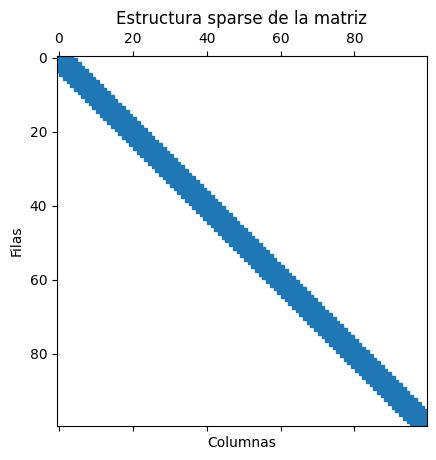

In [5]:
import numpy as np
from scipy.sparse import diags
import matplotlib.pyplot as plt

N = 100

main = 2 * np.ones(N)
off = -1 * np.ones(N-1)

A = diags(
    [off, main, off],
    [-1, 0, 1],
    format="csr"
)

plt.figure()
plt.spy(A)
plt.title("Estructura sparse de la matriz")
plt.xlabel("Columnas")
plt.ylabel("Filas")
plt.show()

`plt.spy()` muestra dónde existen elementos no nulos.

# 5.4 CSR

Una matriz sparse no necesita guardar todos los ceros.

SciPy utiliza formatos como:

$$
\boxed{\text{CSR = Compressed Sparse Row}}
$$

Esto es fundamental para:

* PDEs,
* FEM,
* CFD,
* graph neural networks,
* grandes sistemas lineales,
* simulación científica.

# 6. CONDITIONING

Este concepto es **absolutamente crítico**.

Una matriz puede ser perfectamente invertible y aun así ser numéricamente peligrosa.

# 6.1 La idea

Supón:

$$
Ax=b.
$$

Hay un pequeño error en $(b)$:

$$
b+\delta b.
$$

La solución cambia:

$$
x+\delta x.
$$

Si un pequeño cambio produce un cambio enorme en $(x)$, tenemos un problema mal condicionado.

# 6.2 Número de condición

Para una norma:

$$
\boxed{
\kappa(A)=\|A\|\|A^{-1}\|
}
$$

Para la norma 2:

$$
\boxed{
\kappa_2(A)
=
\frac{\sigma_{\max}}{\sigma_{\min}}
}
$$

si $(A)$ es invertible.

Esto conecta directamente con SVD.

# 6.3 Ejemplo difícil: Hilbert matrix

Una de las matrices clásicas mal condicionadas es:

$$
H_{ij}=\frac1{i+j-1}.
$$

Para \(n=5\):

$$
H=
\begin{bmatrix}
1&1/2&1/3&1/4&1/5\\
1/2&1/3&1/4&1/5&1/6\\
1/3&1/4&1/5&1/6&1/7\\
1/4&1/5&1/6&1/7&1/8\\
1/5&1/6&1/7&1/8&1/9
\end{bmatrix}.
$$

Esta matriz es invertible.

Pero está muy mal condicionada.

# 6.4 Python

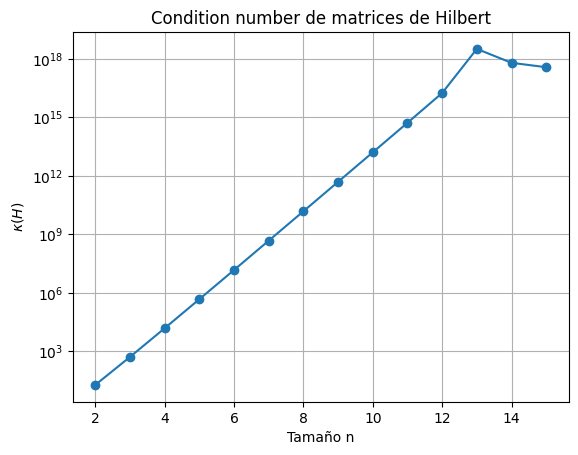

In [6]:
import numpy as np
from scipy.linalg import hilbert

sizes = range(2, 16)

conditions = []

for n in sizes:
    H = hilbert(n)
    conditions.append(np.linalg.cond(H))

import matplotlib.pyplot as plt

plt.figure()
plt.semilogy(sizes, conditions, marker="o")
plt.xlabel("Tamaño n")
plt.ylabel(r"$\kappa(H)$")
plt.title("Condition number de matrices de Hilbert")
plt.grid()
plt.show()

La condición crece extremadamente rápido.

# 6.5 Esto explica algo importante

Supón:

$$
\kappa(A)=10^{10}.
$$

Si tus datos tienen aproximadamente:

$$
10^{-6}
$$

de error relativo, potencialmente puedes tener un error del orden de:

$$
10^{10}\times10^{-6}=10^4.
$$

No significa que siempre ocurra exactamente eso, pero muestra la **sensibilidad potencial**.

# 6.6 Conditioning vs Stability

No confundas:

### Conditioning

Es una propiedad del **problema**.

Pregunta:

> ¿Qué tan sensible es la solución ante pequeñas perturbaciones?

### Stability

Es una propiedad del **algoritmo**.

Pregunta:

> ¿Qué tan bien implementa el algoritmo el problema en aritmética finita?

Puedes tener:

$$
\text{problema bien condicionado + algoritmo malo}
$$

o:

$$
\text{problema mal condicionado + algoritmo excelente}.
$$

# 7. EIGENVALUE PROBLEMS

Ya estudiaste eigenvalues matemáticamente.

Ahora veamos el problema desde el punto de vista numérico.

Queremos:

$$
\boxed{
Av=\lambda v
}
$$

o:

$$
\boxed{
Ax=\lambda Bx
}
$$

en problemas generalizados.

# 7.1 ¿Por qué aparecen en SciML?

Prácticamente en todas partes.

### Vibraciones

$$
M\ddot x+Kx=0.
$$

Buscando:

$$
x(t)=ve^{i\omega t}
$$

obtenemos:

$$
Kv=\omega^2Mv.
$$

Por tanto:

$$
\boxed{\lambda=\omega^2}.
$$

# 7.2 Ejemplo físico: sistema masa-resorte

Imagina tres masas conectadas mediante resortes.

El sistema puede tener modos:

$$
v_1,\quad v_2,\quad v_3.
$$

Cada eigenvector representa una forma particular de vibrar.

Los eigenvalues representan las frecuencias naturales.

Por eso:

> **Eigenvectors = modos físicos**

> **Eigenvalues = escalas/frecuencias asociadas**

# 7.3 Ejemplo

Considera:

$$
K=
\begin{bmatrix}
6&-2&0\\
-2&4&-1\\
0&-1&2
\end{bmatrix}.
$$

Supongamos:

$$
M=I.
$$

Entonces:

$$
Kv=\lambda v.
$$

Podemos calcular:

In [7]:
import numpy as np

K = np.array([
    [6., -2., 0.],
    [-2., 4., -1.],
    [0., -1., 2.]
])

eigenvalues, eigenvectors = np.linalg.eigh(K)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

Eigenvalues:
[1.41577456 3.29428036 7.28994508]

Eigenvectors:
[[ 0.21493528 -0.50489607 -0.8359921 ]
 [ 0.49265588 -0.6830536   0.53919195]
 [ 0.84326331  0.52774779 -0.1019277 ]]


Como $(K)$ es simétrica:

```python
np.linalg.eigh(K)
```

es especialmente apropiado.


# 7.4 Power iteration

Un método iterativo muy importante para eigenvalues es:

$$
x_{k+1}
=
\frac{Ax_k}{\|Ax_k\|}.
$$

Si existe un eigenvalue dominante:

$$
|\lambda_1|>|\lambda_2|\ge\cdots,
$$

entonces:

$$
x_k\to v_1.
$$

Y podemos estimar:

$$
\lambda_1
\approx
\frac{x_k^TAx_k}{x_k^Tx_k}.
$$

# 7.5 Python: power iteration

In [8]:
import numpy as np

A = np.array([
    [5., 2.],
    [2., 2.]
])

x = np.array([1., 1.])

for k in range(30):

    x = A @ x
    x = x / np.linalg.norm(x)

    lam = (x.T @ A @ x) / (x.T @ x)

    print(k, lam)

0 5.984615384615385
1 5.999571367338191
2 5.999988092544742
3 5.999999669236589
4 5.999999990812126
5 5.999999999744782
6 5.9999999999929114
7 5.999999999999803
8 5.999999999999996
9 5.999999999999999
10 6.000000000000001
11 6.0
12 5.999999999999999
13 5.999999999999999
14 6.000000000000001
15 6.0
16 6.0
17 6.000000000000001
18 5.999999999999999
19 6.000000000000002
20 6.0
21 6.000000000000001
22 6.000000000000001
23 6.000000000000001
24 6.000000000000001
25 6.000000000000001
26 6.000000000000001
27 6.000000000000001
28 6.000000000000001
29 6.000000000000001


Verás cómo el eigenvalue converge.

# 7.6 ¿Qué pasa con matrices gigantes?

Supón:

$$
A\in\mathbb R^{10^6\times10^6}.
$$

No quieres calcular todos los eigenvalues.

Quizá solamente necesitas:

* los 5 mayores,
* los 10 menores,
* los modos dominantes.

Entonces utilizas métodos iterativos como:

* Power Method
* Arnoldi
* Lanczos
* Krylov subspace methods

con herramientas como:

```python
scipy.sparse.linalg.eigs
```

o:

```python
scipy.sparse.linalg.eigsh
```

para matrices simétricas.

# 8. LA CONEXIÓN ENTRE TODOS ESTOS MÉTODOS

Aquí está el mapa que quiero que tengas mentalmente:

$$
\boxed{
Ax=b
}
$$

puede resolverse mediante:

### LU

$$
A=LU
$$

### Cholesky

si:

$$
A=A^T,\quad A\succ0
$$

entonces:

$$
A=LL^T.
$$

### QR

$$
A=QR
$$

especialmente útil para:

$$
\min_x\|Ax-b\|_2.
$$

### Iterativos

$$
x_0\to x_1\to x_2\to\cdots
$$

cuando $(A)$ es gigantesca.

### Sparse

Permite representar eficientemente matrices con pocos elementos no nulos.

### Conditioning

Nos dice:

$$
\text{"¿qué tan sensible es el problema?"}
$$

### Eigenvalues

Nos dicen propiedades profundas de:

$$
A.
$$

# 9. UN EJEMPLO REAL DE SCIML QUE LOS UNE TODOS

Esta es la parte que realmente quiero que entiendas.

Supongamos que queremos resolver una ecuación de difusión:

$$
\boxed{
u_t=\alpha u_{xx}
}
$$

con condiciones de frontera.

Discretizamos el espacio.

Entonces:

$$
\mathbf u'(t)=A\mathbf u(t).
$$

La matriz \(A\) es típicamente **sparse**:

$$
A=
\frac{\alpha}{h^2}
\begin{bmatrix}
-2&1&0&\cdots\\
1&-2&1&\cdots\\
0&1&-2&1\\
\vdots&&\ddots
\end{bmatrix}.
$$

Ahora aparecen todos nuestros temas.

## Sparse matrices

La matriz tiene pocos elementos no nulos.

## Eigenvalues

Los eigenvalues de $(A)$ determinan las tasas de decaimiento:

$$
u_i(t)=c_i e^{\lambda_i t}.
$$

## Conditioning

Nos dice qué tan sensible es el sistema.

## Métodos iterativos

Para sistemas grandes:

$$
Ax=b
$$

podemos usar:

$$
CG,\quad GMRES,\quad BiCGSTAB.
$$

## LU

Podemos resolver directamente pequeños o medianos sistemas.

## Cholesky

Si la matriz resultante es simétrica definida positiva, podemos utilizar Cholesky.

## QR

Si estamos estimando parámetros:

$$
\min_\theta\|F(\theta)-y\|^2,
$$

QR puede aparecer.

# 10. Un problema todavía más importante: preconditioning


Cuando estudies métodos iterativos profesionalmente, aparecerá:

$$
\boxed{\text{Preconditioning}}
$$

Supongamos:

$$
Ax=b.
$$

Construimos una matriz $(M)$ fácil de invertir y aproximadamente:

$$
M\approx A.
$$

Entonces resolvemos:

$$
M^{-1}Ax=M^{-1}b.
$$

La solución no cambia, pero el problema puede quedar mucho mejor condicionado para el método iterativo.

Por ejemplo:

$$
\boxed{
M^{-1}A
}
$$

puede tener eigenvalues mucho más agrupados.

Eso puede hacer que CG/GMRES converjan muchísimo más rápido.

| **Inicio**         | **atrás 5**                          |
| ------------------ | ------------------------------------ |
| [🏠](../README.md) | [⏪](./2_5_SVD.ipynb) |